In [1]:
# Setup dataset
import numpy as np
from dynamics_testing import sim, attractor_dist, make_train

SEG, SETTLE, REENTRAIN, N_AUTO, DISCARD, WARM_TRAIN = 2000, 1000, 50, 1200, 200, 200
STATES = ["chaotic", "periodic_A", "periodic_B"]
RS_ROT = 700
N_STEPS = SETTLE + RS_ROT + N_AUTO

def rhs(_, y, b):
    x, yy, z = y
    return [np.sin(yy) - b * x, np.sin(z) - b * yy, np.sin(x) - b * z]

TRAIN = multi_t[:, :4 * SEG] if "multi_t" in globals() else make_train(rhs, SEG)

def make_ref(n_ics, n_steps, seed):
    rng = np.random.default_rng(seed)
    out = {"chaotic": [sim(rhs, 0.18, n_steps, rng.uniform(-4, 4, 3)) for _ in range(n_ics)], "periodic_A": [], "periodic_B": []}
    ex = None
    while min(len(out["periodic_A"]), len(out["periodic_B"])) < n_ics:
        tr = sim(rhs, 0.29, n_steps, rng.uniform(-4, 4, 3)); ex = tr if ex is None else ex
        k = "periodic_A" if attractor_dist(tr, ex) < 0.1 else "periodic_B"
        if len(out[k]) < n_ics: out[k].append(tr)
    return {k: np.concatenate(v, axis=1) for k, v in out.items()}

REF = make_ref(2, 5000, seed=300)
ref_label = lambda tr: min(("periodic_A", "periodic_B"), key=lambda k: attractor_dist(tr, REF[k]))

def make_states(n_ics, n_steps, seed):
    rng = np.random.default_rng(seed)
    out = {"chaotic": [sim(rhs, 0.18, n_steps, rng.uniform(-4, 4, 3)) for _ in range(n_ics)], "periodic_A": [], "periodic_B": []}
    while min(len(out["periodic_A"]), len(out["periodic_B"])) < n_ics:
        tr = sim(rhs, 0.29, n_steps, rng.uniform(-4, 4, 3)); k = ref_label(tr)
        if len(out[k]) < n_ics: out[k].append(tr)
    return out

VAL, TEST = make_states(4, N_STEPS, seed=100), make_states(4, N_STEPS, seed=200)

In [27]:
# Setup model testing harnesses and train model
import testing_harness

RS_OMEGA0 = 0.01
RN_BASE = dict(input_dims=3, spectral_radius=0.6, input_weight=1.2, average_degree_nodes=10, num_nodes=100,
               leakage=0, omega0=RS_OMEGA0, epsilon1=-0.2, epsilon2=0.6,
               mean_phase_tolerance=RS_OMEGA0,          # >= one rotation step, so the pi-crossing can't be skipped
               error_tolerance=np.inf)                  # freeze on phase alone

train_fn, settle_fn = testing_harness.get_harness()["spk"]
net_1, W_1 = train_fn(RN_BASE, 4, 1, TRAIN, WARM_TRAIN, save_hist=True)
net_0, W_0 = train_fn(RN_BASE, 4, 0, TRAIN, WARM_TRAIN, save_hist=True)

In [ ]:
import matplotlib.pyplot as plt

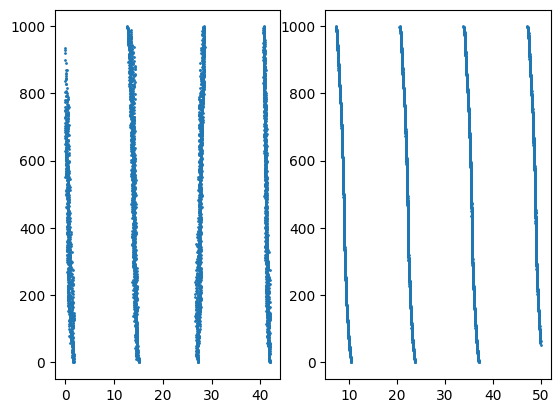

In [29]:
import copy

fig, axes = plt.subplots(1, 2)
for ax, x in zip(axes, (TEST["chaotic"][0], TEST["periodic_A"][0])):
    net = copy.deepcopy(net_1)
    net.reset_initial_states(1); net.reset_history()
    for t in range(SETTLE):
        net.advance(x[:, t], save_history=False)
    order = np.argsort(np.angle(net.rel_lp))               # links sorted by settled offset
    rank = np.empty_like(order); rank[order] = np.arange(len(order))
    t_start, prev, spikes = net.link_time, net.last_spike.copy(), []
    for t in range(SETTLE, SETTLE + 50):
        net.advance(x[:, t], save_history=False)
        new = np.flatnonzero(net.last_spike != prev)
        spikes += [((net.last_spike[i] - t_start) / net.dt_link, rank[i]) for i in new]   # reservoir steps
        prev = net.last_spike.copy()
    s = np.asarray(spikes)
    ax.scatter(s[:, 0], s[:, 1], s=1)
plt.show()

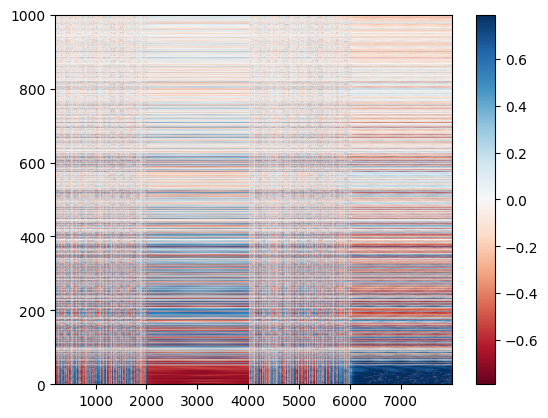

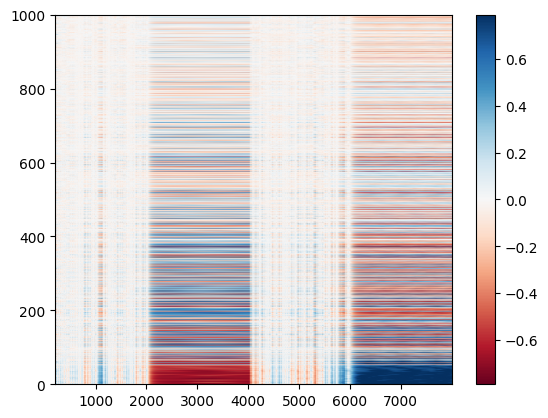

In [35]:
_, _, P, _ = net_1.get_history()                                   # link phases: links x T
psi = np.angle(np.nanmean(np.exp(1j * P), axis=0))                 # global mean phase per step
rel = np.angle(np.exp(1j * (P - psi)))                             # instantaneous offset, wrapped to (-pi, pi]
rel_lp = np.angle(np.asarray(net_1.rel_lp_history)).T              # smoothed offset (what the model uses)

steps = WARM_TRAIN + np.arange(P.shape[1])
per = ((steps // SEG) % 2 == 1) & ((steps % SEG) >= 500)
order = np.argsort(rel_lp[:, per & (steps < 4 * SEG)].mean(axis=1))                    # sort links by settled periodic offset

lim = np.percentile(np.abs(rel_lp), 99)                            # or np.pi for the literal scale
for M in (rel, rel_lp):
    plt.imshow(M[order], aspect="auto", cmap="RdBu", vmin=-lim, vmax=lim,
               extent=[steps[0], steps[-1], 0, M.shape[0]])
    plt.colorbar()
    plt.show()

regime 0: K_eff = 0.0948 rad/step
regime 1: K_eff = 0.1648 rad/step


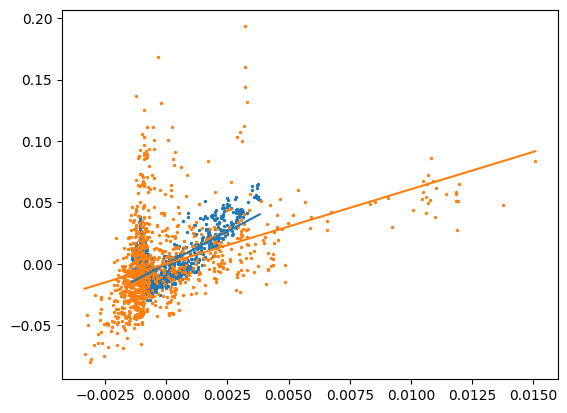

In [30]:
H, _, _, _ = net_1.get_history()                                       # nodes x T
Z = np.asarray(net_1.rel_lp_history)                                   # T x links
drive = (net_1.incidence_T @ ((H + 1) / 2)) / net_1.incidence_norm[:, None]   # links x T
I_ext = np.maximum(net_1.I_ref + net_1.g_freq * (drive - 0.5), net_1.I_ref - 14)  # I_FLOOR = I_c + 1 = I_ref - 14

# natural frequency per link from the measured f-I curve (rad per reservoir step), interpolated
ref = copy.deepcopy(net_1)
I_grid = np.linspace(I_ext.min(), I_ext.max(), 15)
w_grid = np.array([2 * np.pi * ref.dt_link / ref.reference_period(I) for I in I_grid])

steps = WARM_TRAIN + np.arange(Z.shape[0])
regime = (steps // SEG) % 2                                            # 0 chaotic, 1 periodic
steady = (steps % SEG) >= 500                                          # skip context settling after each switch

for r in (0, 1):
    m = (regime == r) & steady
    w = np.interp(I_ext[:, m].mean(axis=1), I_grid, w_grid)
    dw = w - w.mean()                                                  # detuning from the population frequency
    phi = np.angle(Z[m].mean(axis=0))                                  # locked offset from the global mean phase
    K_eff = np.sum(dw ** 2) / np.sum(dw * np.sin(phi))                 # one fitted parameter: sin(phi) = dw / K_eff
    plt.scatter(dw, phi, s=2)
    xs = np.linspace(dw.min(), dw.max(), 200)
    plt.plot(xs, np.arcsin(np.clip(xs / K_eff, -1, 1)))
    print(f"regime {r}: K_eff = {K_eff:.4f} rad/step")
plt.show()

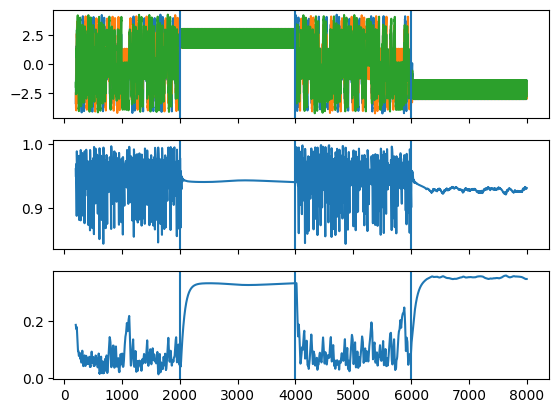

In [31]:
_, _, _, U = net_1.get_history()                                       # 3 x T training input
R, _ = net_1.get_global_parameters()                                   # read-only
Z = np.asarray(net_1.rel_lp_history)                                   # T x links

steps = WARM_TRAIN + np.arange(Z.shape[0])
ref_mask = ((steps // SEG) % 2 == 0) & ((steps % SEG) >= 500)          # steady part of the chaotic segments
ref_mask &= steps < 2 * SEG                                            # first chaotic segment only
ctx = np.sqrt(np.mean(np.abs(Z - Z[ref_mask].mean(axis=0)) ** 2, axis=1))

fig, axes = plt.subplots(3, 1, sharex=True)
axes[0].plot(steps, U.T)
axes[1].plot(steps, R)
axes[2].plot(steps, ctx)
for ax in axes:
    for b in range(SEG, steps[-1] + 1, SEG):
        ax.axvline(b)
plt.show()

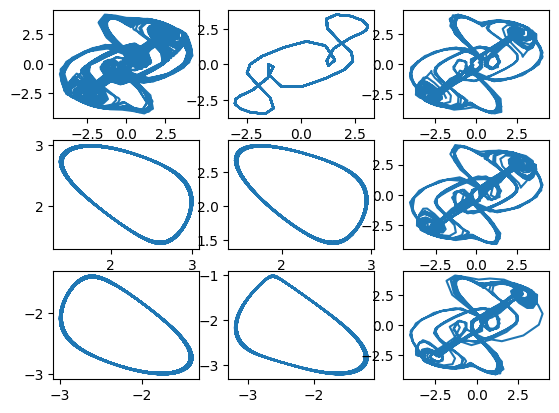

In [39]:
BEST = {'RN_c0': 0.1, 'RN_pub': 1e-08, 'spike_c0': 0.1, 'spike_c1.0': 0.01}

nets = {}
for name, net, key in (("c1", net_1, "spike_c1.0"), ("c0", net_0, "spike_c0")):
    n = copy.deepcopy(net)
    n.regularization = BEST[key]
    n.compute_weights()                                                # readout at the alpha chosen on validation
    nets[name] = n

states = ["chaotic", "periodic_A", "periodic_B"]
fig, axes = plt.subplots(len(states), 3)
for row, s in zip(axes, states):
    x = TEST[s][0]
    row[0].plot(x[0, SETTLE:], x[1, SETTLE:])
    for ax, name in zip(row[1:], ("c1", "c0")):
        p, _ = copy.deepcopy(nets[name]).predict(x, SETTLE, REENTRAIN, N_AUTO, offset=1)
        ax.plot(p[0, DISCARD:], p[1, DISCARD:])
plt.show()

100%|████████████████████████████████████████████████████████████████████████████████| 50/50 [00:00<00:00, 2577.34it/s]


steps 0-467: context chaotic     -> output chaotic
steps 467-867: context periodic_A  -> output periodic_A
steps 867-1269: context chaotic     -> output none
steps 1269-1669: context periodic_B  -> output periodic_B
steps 1669-2069: context chaotic     -> output chaotic


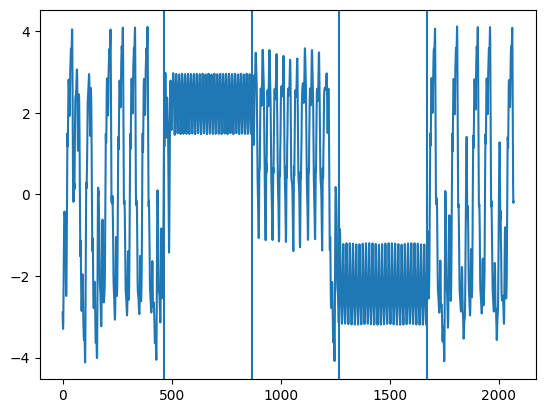

In [58]:
from scipy.spatial import cKDTree
from dynamics_testing import classify

# readout at the validation alpha (on a copy)
net = copy.deepcopy(net_1)
net.regularization = BEST["spike_c1.0"]
net.compute_weights()

def settle(x, offset=1):
    w = copy.deepcopy(net)
    w.reset_initial_states(offset); w.reset_history()
    for t in range(SETTLE):
        w.advance(x[:, t], save_history=False)
    return w

# frozen contexts: chaotic from IC 2 (lambda ~ true value), periodic from IC 0 of each orbit
Z = {"chaotic":    settle(TEST["chaotic"][2], offset=3).rel_lp.copy(),
     "periodic_A": settle(TEST["periodic_A"][0], offset=1).rel_lp.copy(),
     "periodic_B": settle(TEST["periodic_B"][0], offset=1).rel_lp.copy()}

# switch into a periodic context only when the output is nearer (3-D) to that orbit than to the other
TREE = {s: cKDTree(REF[s].T) for s in ("periodic_A", "periodic_B")}
def nearer(out, target):
    other = "periodic_B" if target == "periodic_A" else "periodic_A"
    return TREE[target].query(out)[0] < TREE[other].query(out)[0]

# start: settle and re-entrain on chaotic drive, then run autonomously
x = TEST["chaotic"][2]
w = settle(x, offset=3)
w.frozen = True
for t in tqdm(range(SETTLE, SETTLE + REENTRAIN)):
    w.advance_nodes(x[:, t], save_history=False)

SCHEDULE = [("chaotic", 400), ("periodic_A", 400), ("chaotic", 400), ("periodic_B", 400), ("chaotic", 400)]
HOLD, MAX_WAIT = 3, 400                       # steps the output must stay near the target orbit; cap on waiting
P, bounds = [], [0]
for k, (s, n) in enumerate(SCHEDULE):
    w.rel_lp = Z[s].copy()                    # swap the frozen context; no input from here on
    nxt = SCHEDULE[k + 1][0] if k + 1 < len(SCHEDULE) else None
    run = 0
    for step in range(n + MAX_WAIT):
        out = w.output_weights @ w.node_states
        if step >= n:                         # minimum segment length reached: decide when to switch
            if nxt not in TREE:
                break                         # next segment is chaotic (or none): switch now
            run = run + 1 if nearer(out, nxt) else 0
            if run >= HOLD:
                break                         # output is in the next orbit's region: switch now
        P.append(out)
        w.advance_nodes(out, save_history=False)
    bounds.append(len(P))
P = np.asarray(P).T

for (s, _), a, b in zip(SCHEDULE, bounds[:-1], bounds[1:]):
    print(f"steps {a}-{b}: context {s:11s} -> output {classify(P[:, b - 300:b], REF)[0]}")
plt.plot(P[0])
for b in bounds[1:-1]:
    plt.axvline(b)
plt.show()

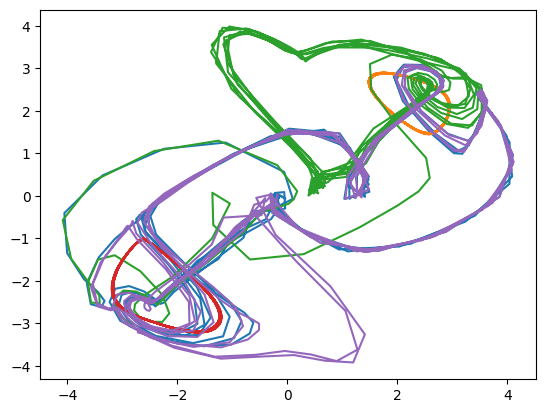

In [59]:
plt.plot(P[0, bounds[1] - 300:bounds[1]], P[1, bounds[1] - 300:bounds[1]])   # segment 1: chaotic context
plt.plot(P[0, bounds[2] - 300:bounds[2]], P[1, bounds[2] - 300:bounds[2]])   # segment 2: periodic_A context
plt.plot(P[0, bounds[3] - 300:bounds[3]], P[1, bounds[3] - 300:bounds[3]])   # segment 3: chaotic context
plt.plot(P[0, bounds[4] - 300:bounds[4]], P[1, bounds[4] - 300:bounds[4]])   # segment 4: periodic_B context
plt.plot(P[0, bounds[5] - 300:bounds[5]], P[1, bounds[5] - 300:bounds[5]])   # segment 5: chaotic context
plt.show()

100%|████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:17<00:00,  8.65s/it]


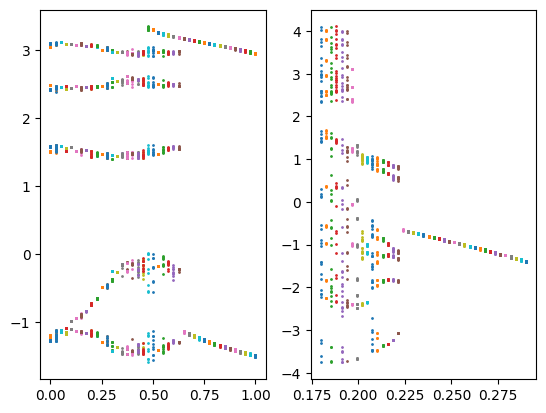

In [48]:
from dynamics_testing import sim

net = copy.deepcopy(net_1)
net.regularization = BEST["spike_c1.0"]
net.compute_weights()

def settle(x, offset=1):
    w = copy.deepcopy(net)
    w.reset_initial_states(offset); w.reset_history()
    for t in range(SETTLE):
        w.advance(x[:, t], save_history=False)
    return w

def maxima(v):
    return v[1:-1][(v[1:-1] > v[:-2]) & (v[1:-1] > v[2:])]

z_ch = settle(TEST["chaotic"][0]).rel_lp.copy()
z_per = settle(TEST["periodic_A"][0]).rel_lp.copy()
A = np.linspace(0, 1, 41)
N_TRANS, N_REC = 300, 500

# start autonomous from the chaotic settle, then sweep the context adiabatically (state carried over)
x = TEST["chaotic"][0]
w0 = settle(x)
w0.frozen = True
for t in range(SETTLE, SETTLE + REENTRAIN):
    w0.advance_nodes(x[:, t], save_history=False)

fig, axes = plt.subplots(1, 2)
for sweep in tqdm((A, A[::-1])):                                              # forward and backward: shows hysteresis
    w = copy.deepcopy(w0)
    for a in sweep:
        w.rel_lp = (1 - a) * z_ch + a * z_per
        xs = []
        for k in range(N_TRANS + N_REC):
            out = w.output_weights @ w.node_states
            if k >= N_TRANS:
                xs.append(out[0])
            w.advance_nodes(out, save_history=False)
        m = maxima(np.asarray(xs))
        axes[0].scatter(np.full(len(m), a), m, s=1)

# ground truth: Thomas over lambda
for b in np.linspace(0.18, 0.29, 41):
    m = maxima(sim(rhs, b, N_REC, (0.1, 0.0, -0.1))[0])
    axes[1].scatter(np.full(len(m), b), m, s=1)
plt.show()